**DAY-1 MICROSOFT MACHINE LEARNING WORKSHOP**
30 October 2026


In [ ]:
import os
DATA = 'data/' if os.path.exists('data/retail_orders.csv') else ''
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 20)
print('Ready. Files found:', [f for f in os.listdir(DATA or '.') if f.endswith('.csv')])

Ready. Files found: ['student_marks.csv', 'retail_orders.csv', 'job_postings_skills.csv', 'delhi_air_quality_2025.csv']


**DEMO-1**

**5 insights from Delhi air quality**

**Question:** How bad is Delhi's air, when, and where?:

In [ ]:
aq = pd.read_csv(DATA + 'delhi_air_quality_2025.csv', parse_dates=['date'])
print(aq.shape)
aq.head()

(1825, 6)


,date,station,pm25,pm10,aqi,aqi_category
0,2025-01-01,Anand Vihar,151.9,291.7,325.0,Very Poor
1,2025-01-02,Anand Vihar,107.3,191.5,257.0,Poor
2,2025-01-03,Anand Vihar,209.9,418.8,369.0,Very Poor
3,2025-01-04,Anand Vihar,171.4,289.5,340.0,Very Poor
4,2025-01-05,Anand Vihar,173.2,303.0,341.0,Very Poor


In [ ]:
# Insight 1: data types and missing values
aq.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1825 non-null   datetime64[ns]
 1   station       1825 non-null   object        
 2   pm25          1787 non-null   float64       
 3   pm10          1787 non-null   float64       
 4   aqi           1787 non-null   float64       
 5   aqi_category  1787 non-null   object        
dtypes: datetime64[ns](1), float64(3), object(2)
memory usage: 85.7+ KB


In [ ]:
# Insight 2: average AQI by month - which months are worst?
aq['month'] = aq['date'].dt.month
aq.groupby('month')['aqi'].mean().round(0)

,aqi
month,
1,313.0
2,252.0
3,167.0
4,143.0
5,165.0
6,115.0
7,64.0
8,62.0
9,74.0


In [ ]:
# Insight 3: which station has the worst average AQI?
aq.groupby('station')['aqi'].mean().sort_values(ascending=False).round(0)

,aqi
station,
Anand Vihar,227.0
ITO,205.0
R K Puram,186.0
Dwarka,174.0
Lodhi Road,162.0


In [ ]:
# Insight 4: how many station-days fall in each AQI category?
aq['aqi_category'].value_counts()

,count
aqi_category,
Satisfactory,525
Very Poor,477
Moderate,401
Poor,280
Good,73
Severe,31


In [ ]:
# Insight 5: the 5 worst readings of the year
aq.sort_values('aqi', ascending=False).head(5)[['date', 'station', 'pm25', 'aqi', 'aqi_category']]

,date,station,pm25,aqi,aqi_category
671,2025-11-03,ITO,360.9,445.0,Severe
315,2025-11-12,Anand Vihar,348.1,440.0,Severe
674,2025-11-06,ITO,335.1,434.0,Severe
307,2025-11-04,Anand Vihar,330.1,432.0,Severe
305,2025-11-02,Anand Vihar,323.8,430.0,Severe


**Demo 2**

**NumPy: fast maths on whole arrays**

**Question:** How did the class perform, and who needs support?


In [ ]:
sm = pd.read_csv(DATA + 'student_marks.csv')
subjects = ['python', 'statistics', 'mathematics', 'english', 'data_handling']
marks = sm[subjects].to_numpy()      # a 2-D NumPy array: 60 rows x 5 columns
print(type(marks), marks.shape, marks.dtype)
marks[:5]

<class 'numpy.ndarray'> (60, 5) int64


array([[57, 46, 43, 73, 59],
       [72, 64, 56, 84, 61],
       [54, 48, 48, 61, 58],
       [78, 73, 59, 63, 63],
       [63, 61, 64, 77, 57]])

In [ ]:
# Vectorised statistics - no loops
print('Subject averages :', marks.mean(axis=0).round(1))
print('Student averages (first 5):', marks.mean(axis=1)[:5].round(1))
print('Highest in each subject:', marks.max(axis=0))
print('Spread (std dev) :', marks.std(axis=0).round(1))

Subject averages : [69.9 63.6 63.2 71.9 67.2]
Student averages (first 5): [55.6 67.4 53.8 67.2 64.4]
Highest in each subject: [97 83 94 92 98]
Spread (std dev) : [10.2 11.2 12.   8.  10.1]


In [ ]:
# Broadcasting: add 5 grace marks to everyone, capped at 100
graced = np.minimum(marks + 5, 100)
print(graced[:3])

[[62 51 48 78 64]
 [77 69 61 89 66]
 [59 53 53 66 63]]


In [ ]:
# Boolean masks: pass = 40 or more in EVERY subject
passed_all = (marks >= 40).all(axis=1)
print('Passed all subjects:', passed_all.sum(), 'of', len(marks))
print('Pass rate:', round(passed_all.mean() * 100, 1), '%')

Passed all subjects: 57 of 60
Pass rate: 95.0 %


In [ ]:
# Toppers: index of the highest total
totals = marks.sum(axis=1)
top3 = np.argsort(totals)[::-1][:3]
sm.loc[top3, ['roll_no', 'course']].assign(total=totals[top3])

,roll_no,course,total
58,MSC25059,B.Sc. (H) Computer Science,463
49,MSC25050,B.Sc. (H) Computer Science,408
23,MSC25024,B.Sc. (H) Mathematics,397


In [ ]:
# Why vectorise? Loop vs NumPy on 1 million numbers
big = np.random.default_rng(0).integers(0, 100, 1_000_000)
import time
t = time.time(); s = 0
for v in big: s += v
loop = time.time() - t
t = time.time(); s2 = big.sum(); vec = time.time() - t
print(f'loop {loop:.3f}s vs numpy {vec:.4f}s -> about {loop / max(vec, 1e-6):.0f}x faster')

loop 0.428s vs numpy 0.0015s -> about 280x faster


## Demo 3 - pandas: explore, clean, filter, group
**Question:** Which cities and categories drive sales for an online store, and is the data trustworthy?

In [ ]:
ro = pd.read_csv(DATA + 'retail_orders.csv', parse_dates=['order_date'])
print(ro.shape)
ro.head()

(1208, 9)


,order_id,order_date,city,category,product,quantity,unit_price,payment_mode,customer_type
0,ORD101103,2025-01-01,Delhi,Fashion,Sneakers,1,1999,UPI,New
1,ORD101188,2025-01-01,Chennai,Electronics,Bluetooth Speaker,1,1799,UPI,New
2,ORD100728,2025-01-02,Delhi,Electronics,Earbuds,1,1499,UPI,Returning
3,ORD101046,2025-01-02,Chandigarh,Beauty,Face Wash,2,249,UPI,Returning
4,ORD101058,2025-01-02,Hyderabad,Fashion,Sneakers,1,1999,Card,Returning


In [ ]:
ro.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1208 entries, 0 to 1207
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       1208 non-null   object        
 1   order_date     1208 non-null   datetime64[ns]
 2   city           1193 non-null   object        
 3   category       1208 non-null   object        
 4   product        1208 non-null   object        
 5   quantity       1208 non-null   int64         
 6   unit_price     1208 non-null   int64         
 7   payment_mode   1199 non-null   object        
 8   customer_type  1208 non-null   object        
dtypes: datetime64[ns](1), int64(2), object(6)
memory usage: 85.1+ KB


In [ ]:
ro.describe()   # note: min quantity is negative -> returns

,order_date,quantity,unit_price
count,1208,1208.000000,1208.000000
mean,2025-07-17 16:12:42.913907200,1.932947,951.359272
min,2025-01-01 00:00:00,-4.000000,149.000000
25%,2025-04-09 00:00:00,1.000000,399.000000
50%,2025-07-28 12:00:00,2.000000,799.000000
75%,2025-10-25 00:00:00,3.000000,1299.000000
max,2025-12-31 00:00:00,4.000000,2999.000000
std,NaN,1.108665,718.368178


In [ ]:
# Data-quality checks (always do these first)
print('Missing values:\n', ro.isna().sum(), '\n')
print('Duplicate rows:', ro.duplicated().sum())
print('Returns (negative quantity):', (ro['quantity'] < 0).sum())

Missing values:
 order_id          0
order_date        0
city             15
category          0
product           0
quantity          0
unit_price        0
payment_mode      9
customer_type     0
dtype: int64 

Duplicate rows: 8
Returns (negative quantity): 12


In [ ]:
# Clean: remove duplicates, label missing values, separate returns
clean = ro.drop_duplicates().copy()
clean['city'] = clean['city'].fillna('Unknown')
clean['payment_mode'] = clean['payment_mode'].fillna('Not recorded')
returns = clean[clean['quantity'] < 0]
sales = clean[clean['quantity'] > 0].copy()
sales['amount'] = sales['quantity'] * sales['unit_price']
print(len(ro), '->', len(clean), 'rows after removing duplicates;', len(returns), 'returns set aside')

1208 -> 1200 rows after removing duplicates; 12 returns set aside


In [ ]:
# Filter: big orders from Delhi
sales[(sales['city'] == 'Delhi') & (sales['amount'] >= 3000)].head()

,order_id,order_date,city,category,product,quantity,unit_price,payment_mode,customer_type,amount
19,ORD100366,2025-01-07,Delhi,Electronics,Power Bank,4,999,UPI,Returning,3996
81,ORD101071,2025-01-28,Delhi,Electronics,Smart Watch,4,2999,Card,Returning,11996
93,ORD100461,2025-02-01,Delhi,Electronics,Earbuds,3,1499,UPI,Returning,4497
97,ORD100542,2025-02-02,Delhi,Electronics,Earbuds,3,1499,UPI,Returning,4497
148,ORD100592,2025-02-20,Delhi,Fashion,Jeans,4,1299,Cash on Delivery,Returning,5196


In [ ]:
# Group: sales by city
sales.groupby('city')['amount'].sum().sort_values(ascending=False)

,amount
city,
Delhi,474448
Mumbai,344698
Bengaluru,323954
Kolkata,178684
Chennai,171167
Hyderabad,167001
Pune,148654
Jaipur,135661
Chandigarh,114444


In [ ]:
# Group by two columns + several measures
sales.groupby('category').agg(orders=('order_id', 'count'), revenue=('amount', 'sum'), avg_order=('amount', 'mean')).round(0).sort_values('revenue', ascending=False)

,orders,revenue,avg_order
category,,,
Electronics,275,962147,3499.0
Fashion,314,668391,2129.0
Home & Kitchen,193,254909,1321.0
Books & Stationery,236,207597,880.0
Beauty,170,107015,630.0


In [ ]:
# Payment preferences (share of orders)
(sales['payment_mode'].value_counts(normalize=True) * 100).round(1)

,proportion
payment_mode,
UPI,53.5
Card,19.4
Cash on Delivery,18.4
Net Banking,7.9
Not recorded,0.8


**Demo 4 - Charts that answer a question**

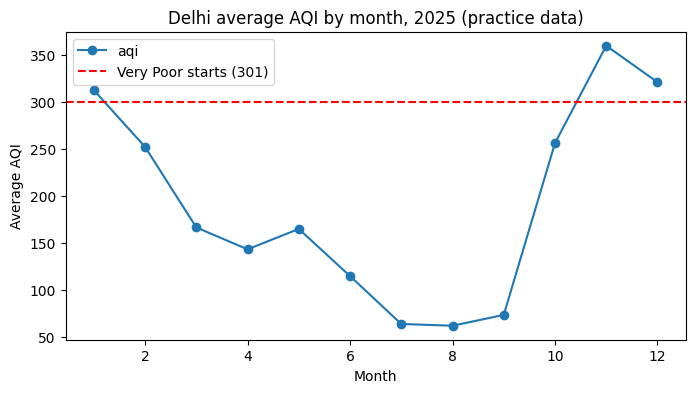

In [ ]:
monthly = aq.groupby('month')['aqi'].mean()
ax = monthly.plot(kind='line', marker='o', figsize=(8, 4), title='Delhi average AQI by month, 2025 (practice data)')
ax.axhline(300, color='red', linestyle='--', label='Very Poor starts (301)')
ax.set_xlabel('Month'); ax.set_ylabel('Average AQI'); ax.legend(); plt.show()

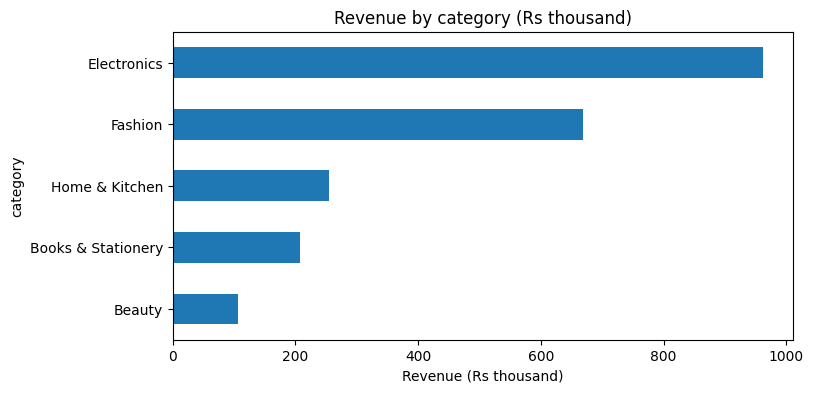

In [ ]:
by_cat = sales.groupby('category')['amount'].sum().sort_values()
ax = (by_cat / 1000).plot(kind='barh', figsize=(8, 4), title='Revenue by category (Rs thousand)')
ax.set_xlabel('Revenue (Rs thousand)'); plt.show()

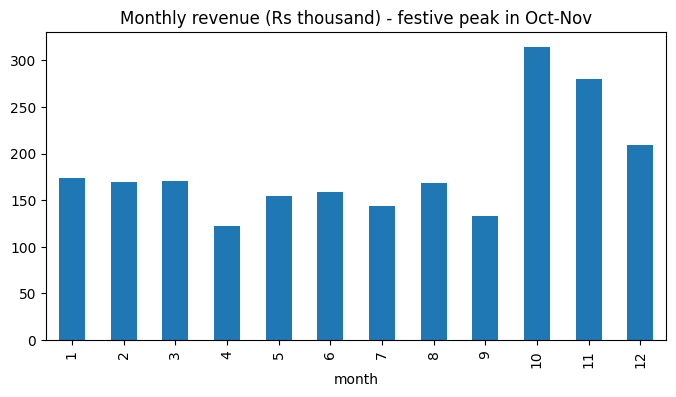

In [ ]:
sales['month'] = sales['order_date'].dt.month
(sales.groupby('month')['amount'].sum() / 1000).plot(kind='bar', figsize=(8, 4), title='Monthly revenue (Rs thousand) - festive peak in Oct-Nov')
plt.show()

**Chart rules:** one question per chart · title says the answer · label axes with units · line for time, bar for comparing groups.

**Demo 5 - Case CS-01: what do data jobs actually ask for?**

In [ ]:
jp = pd.read_csv(DATA + 'job_postings_skills.csv')
print(jp.shape)
jp.head()

(48, 6)


,posting_id,role,job_title,location,experience_years,skills
0,JP013,Data Engineer,Associate Data Engineer,Pune,0,Spark; Python; SQL; ETL
1,JP039,AI Engineer,GenAI Developer,Bengaluru,0,Prompt Engineering; RAG; Machine Learning; APIs
2,JP010,Data Analyst,Business Analyst,Pune,2,Statistics; Power BI; Communication; SQL; Pyth...
3,JP046,AI Engineer,Associate AI Engineer,Mumbai,2,Machine Learning; Python; RAG; LLM APIs
4,JP032,Data Scientist,Junior Data Scientist,Delhi NCR,0,Statistics; Machine Learning; SQL; Communication


In [ ]:
jp['role'].value_counts()

,count
role,
Data Engineer,12
AI Engineer,12
Data Analyst,12
Data Scientist,12


In [ ]:
# Split the skills text into one row per skill
skills = jp.assign(skill=jp['skills'].str.split('; ')).explode('skill').reset_index(drop=True)
skills[['posting_id', 'role', 'skill']].head(8)

,posting_id,role,skill
0,JP013,Data Engineer,Spark
1,JP013,Data Engineer,Python
2,JP013,Data Engineer,SQL
3,JP013,Data Engineer,ETL
4,JP039,AI Engineer,Prompt Engineering
5,JP039,AI Engineer,RAG
6,JP039,AI Engineer,Machine Learning
7,JP039,AI Engineer,APIs


In [ ]:
# Top 5 skills per role
top = skills.groupby(['role', 'skill']).size().rename('postings').reset_index()
top.sort_values(['role', 'postings'], ascending=[True, False]).groupby('role').head(5)

,role,skill,postings
6,AI Engineer,Python,9
7,AI Engineer,RAG,9
2,AI Engineer,Git,7
4,AI Engineer,Machine Learning,7
5,AI Engineer,Prompt Engineering,7
13,Data Analyst,Python,11
11,Data Analyst,Excel,10
14,Data Analyst,SQL,10
15,Data Analyst,Statistics,8
16,Data Analyst,Tableau,8


In [ ]:
# Role x skill map (how many postings ask for each skill)
matrix = pd.crosstab(skills['skill'], skills['role'])
matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index].head(12)

role,AI Engineer,Data Analyst,Data Engineer,Data Scientist
skill,,,,
Python,9,11,7,8
SQL,0,10,9,9
Statistics,0,8,0,12
Machine Learning,7,0,0,10
Git,7,0,2,2
pandas,0,4,0,6
Excel,0,10,0,0
Communication,0,5,0,5
RAG,9,0,0,0


In [ ]:
# Skills that appear in all four roles
common = matrix[(matrix > 0).all(axis=1)].index.tolist()
print('Asked for by all four roles:', common)

Asked for by all four roles: ['Python']
